# <div align="center">🧬 Machine Learning for *In Silico* Bioactivity Prediction<br><sub>SARS-CoV-2 Main Protease ($M^{pro}$) Inhibitors</sub></div>

<div align="center">

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wanwisa-laoloet/ML-In-Silico-Bioactivity-Prediction-and-Structure-Activity-Relationship/blob/main/notebooks/SARS_CoV_2_Mpro_Bioactivity_Prediction.ipynb)
![Python](https://img.shields.io/badge/Python-3.10%2B-blue?logo=python)
![RDKit](https://img.shields.io/badge/RDKit-Cheminformatics-teal?logo=chemistry)
![XGBoost](https://img.shields.io/badge/Model-XGBoost%20%7C%20RF%20%7C%20SVR-orange)
![SHAP](https://img.shields.io/badge/XAI-SHAP%20Explainable-purple)
![License](https://img.shields.io/badge/License-MIT-green)

</div>

---

### 📋 ข้อมูลโครงงานวิทยาการข้อมูล (Computer Science Project — CP352101)
> **ชื่อโครงงาน:** การประยุกต์ใช้การเรียนรู้ของเครื่องเพื่อทำนายฤทธิ์ทางชีวภาพและวิเคราะห์ความสัมพันธ์ระหว่างโครงสร้างกับฤทธิ์ของสารยับยั้ง SARS-CoV-2 Main Protease แบบ *In Silico*  
> **สาขาวิชา:** สาขาวิชาวิทยาการคอมพิวเตอร์ วิทยาลัยการคอมพิวเตอร์ มหาวิทยาลัยขอนแก่น  
> **ผู้จัดทำ:**  
> 1. นายรุ่งธรรม ล้อมในเมือง (รหัสนักศึกษา 6633800639-0)  
> 2. นางสาววรรณวิษา เลาเลิศ (รหัสนักศึกษา 683380668-7)  
> **อาจารย์ที่ปรึกษา:** อาจารย์ธนพล ตั้งชูพงศ์  
> **GitHub Repository:** [wanwisa-laoloet/ML-In-Silico-Bioactivity-Prediction-and-Structure-Activity-Relationship](https://github.com/wanwisa-laoloet/ML-In-Silico-Bioactivity-Prediction-and-Structure-Activity-Relationship)

---

### 🎯 สารบัญการดำเนินงาน (Table of Contents)
1. **[Section 1]** การติดตั้งไลบรารีและตั้งค่าสภาพแวดล้อม (Environment & Dependencies)
2. **[Section 2]** การโหลดข้อมูลและการทำความสะอาดข้อมูลเคมี (Data Loading & 13-Step Curation)
3. **[Section 3]** การสกัดคุณลักษณะโมเลกุลแบบผสม 1,028 มิติ (Hybrid Feature Engineering)
4. **[Section 4]** การสำรวจข้อมูลและการแจกแจงปริภูมิเคมี (Exploratory Data Analysis: EDA)
5. **[Section 5]** การสร้าง Pipeline ป้องกัน Data Leakage (Leakage-Safe Modeling Pipeline)
6. **[Section 6]** การเปรียบเทียบแบบจำลองด้วย 5-Fold Cross Validation
7. **[Section 7]** การประเมินความสามารถทำนายโครงสร้างใหม่ (Random Split vs Bemis-Murcko Scaffold Split)
8. **[Section 8]** ปัญญาประดิษฐ์ที่อธิบายได้ (Explainable AI: SHAP & 2D Substructure Bit Mapping)
9. **[Section 9]** การทดสอบภายนอกและขอบเขตการใช้งานแบบจำลอง (External Validation & Applicability Domain)
10. **[Section 10]** ระบบทำนายฤทธิ์สารโมเลกุลแบบโต้ตอบ (*In Silico* Interactive Prediction Tool)

## 📦 1. ติดตั้งไลบรารีที่จำเป็น (Installation & Dependencies)
ติดตั้ง **RDKit** สำหรับประมวลผลสารเคมีเชิงคำนวณ (Cheminformatics), **XGBoost** สำหรับอัลกอริทึม Gradient Boosting, และ **SHAP** สำหรับการอธิบายแบบจำลองเชิงลึก

In [4]:
# ติดตั้งไลบรารีที่จำเป็นใน Google Colab
!pip install -q rdkit xgboost shap pyarrow seaborn joblib
print("✅ ติดตั้งไลบรารีสำเร็จเรียบร้อย!")

✅ ติดตั้งไลบรารีสำเร็จเรียบร้อย!


## ⚙️ 2. นำเข้าไลบรารีและกำหนดค่าคงที่ (Imports & Configuration)

In [5]:
import os
import sys
import json
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# Cheminformatics (RDKit)
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import Descriptors, Lipinski, rdFingerprintGenerator, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold

# Machine Learning (Scikit-Learn & XGBoost)
from sklearn.model_selection import KFold, train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
import shap

# ปิด Warning เพื่อความสะอาดของรายงานผล
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")

# ตั้งค่าธีมกราฟ
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# กำหนด Hyperparameters และค่าคงที่
RANDOM_STATE = 42
CV_FOLDS = 5
FP_RADIUS = 2
FP_BITS = 1024
DESC_COLS = ["MW", "LogP", "NumHDonors", "NumHAcceptors"]
FP_COLS = [f"bit_{i}" for i in range(FP_BITS)]
FEATURE_COLS = FP_COLS + DESC_COLS

print(f"🚀 ตั้งค่าสภาพแวดล้อมพร้อมใช้งาน (Random Seed = {RANDOM_STATE})")

🚀 ตั้งค่าสภาพแวดล้อมพร้อมใช้งาน (Random Seed = 42)


## 📥 3. ดาวน์โหลดและโหลดชุดข้อมูล (Data Loading)
โหลดชุดข้อมูลสารเคมีที่ผ่านกระบวนการคัดกรอง 13 ขั้นตอน (Curated Dataset) จำนวน 2,198 สาร จากฐานข้อมูล ChEMBL (Target: SARS-CoV-2 Main Protease `CHEMBL4523582`) โดยดึงตรงจาก GitHub Repository ของโครงงานโดยอัตโนมัติ

In [7]:
# URL ชุดข้อมูลจาก GitHub Repository
BASE_GITHUB_RAW = "https://raw.githubusercontent.com/wanwisa-laoloet/ML-In-Silico-Bioactivity-Prediction-and-Structure-Activity-Relationship/main"
MASTER_DATA_URL = f"{BASE_GITHUB_RAW}/data/processed/clean_bioactivity_master.csv"
EXTERNAL_DATA_URL = f"{BASE_GITHUB_RAW}/data/processed/external_ddh_clean.csv"

# โหลดข้อมูลเข้าสู่ DataFrame
df_master = pd.read_csv(MASTER_DATA_URL)
print(f"✅ โหลดข้อมูลจาก GitHub Raw สำเร็จ: clean_bioactivity_master.csv (รูปร่าง: {df_master.shape})")

# แสดงตัวอย่างข้อมูล 5 แถวแรก
df_master[["molecule_chembl_id", "canonical_smiles", "ic50_nM", "pIC50", "bioactivity_class"]].head(5)

✅ โหลดข้อมูลจาก GitHub Raw สำเร็จ: clean_bioactivity_master.csv (รูปร่าง: (2198, 10))


,molecule_chembl_id,canonical_smiles,ic50_nM,pIC50,bioactivity_class
0,CHEMBL385315,CC(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@@H](CC(C)C)C...,53000.00000,4.275724,inactive
1,CHEMBL6148266,CC(C)(C)OC(=O)N[C@H](C(=O)N[C@@H](CSCc1ccccc1)...,47.00000,7.327902,active
2,CHEMBL5192607,CC(=O)OCC1Cc2c(-c3ccc(N(C)C)cn3)cccc2-c2c(O)cc...,4654.80397,5.332099,intermediate
3,CHEMBL1200397,CN(Cc1ccc(C(C)(C)C)cc1)Cc1cccc2ccccc12,5400.00000,5.267606,intermediate
4,CHEMBL6143060,CC(C)C[C@@H](C(=O)N1C[C@]2(C[C@H]1C#N)C(=O)Nc1...,24.34000,7.613679,active


## 🧬 4. การสกัดคุณลักษณะโมเลกุลแบบผสม (Hybrid Feature Extraction: 1,028 มิติ)
การแปลงโครงสร้างเคมี SMILES ให้เป็นเวกเตอร์ตัวเลขทางคณิตศาสตร์ 1,028 มิติ:
1. **Morgan Fingerprints (ECFP4):** รัศมี 2 บิตแมป 1,024 บิต (จับภาพโครงสร้างย่อย 2 มิติระดับอะตอม)
2. **Lipinski Descriptors:** คุณสมบัติทางเคมีกายภาพ 4 ค่า (MW, LogP, HBD, HBA) ตามกฎของลิพินสกี

$$\text{Total Features} = 1{,}024 \text{ (Morgan Bits)} + 4 \text{ (Lipinski Descriptors)} = 1{,}028 \text{ มิติ}$$

In [8]:
_gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_BITS)

def featurize_molecule(smiles, keep_bitinfo=False):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None, None, None
    ao = rdFingerprintGenerator.AdditionalOutput()
    if keep_bitinfo:
        ao.AllocateBitInfoMap()
    fp = _gen.GetFingerprintAsNumPy(mol, additionalOutput=ao)
    desc = [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol)
    ]
    bitinfo = ao.GetBitInfoMap() if keep_bitinfo else None
    return fp.astype(np.uint8), desc, bitinfo

# สกัดคุณลักษณะโมเลกุลทั้ง 2,198 รายการ
print("⏳ กำลังสกัดคุณลักษณะ 1,028 มิติ สำหรับทุกโมเลกุล...")
fps, descs, valid_idx = [], [], []

for i, smi in enumerate(df_master["canonical_smiles"]):
    fp, desc, _ = featurize_molecule(smi)
    if fp is not None:
        fps.append(fp)
        descs.append(desc)
        valid_idx.append(i)

X_fp = pd.DataFrame(np.vstack(fps), columns=FP_COLS)
X_desc = pd.DataFrame(np.array(descs), columns=DESC_COLS)
X = pd.concat([X_fp, X_desc], axis=1)
y = df_master.iloc[valid_idx]["pIC50"].values

print(f"✅ สกัดคุณลักษณะสำเร็จ! รูปร่างของเมทริกซ์ X: {X.shape}, ป้ายกำกับ y: {len(y)}")
X[DESC_COLS].describe().round(2)

⏳ กำลังสกัดคุณลักษณะ 1,028 มิติ สำหรับทุกโมเลกุล...
✅ สกัดคุณลักษณะสำเร็จ! รูปร่างของเมทริกซ์ X: (2198, 1028), ป้ายกำกับ y: 2198


,MW,LogP,NumHDonors,NumHAcceptors
count,2198.00,2198.00,2198.00,2198.00
mean,453.42,3.05,2.22,5.18
std,123.60,1.74,1.66,1.95
min,107.16,-5.02,0.00,1.00
25%,352.44,1.78,1.00,4.00
50%,472.97,2.91,2.00,5.00
75%,533.62,4.15,3.00,6.00
max,973.13,8.62,12.00,18.00


## 📊 5. การสำรวจข้อมูลและปริภูมิเคมี (Exploratory Data Analysis: EDA)
แสดงการกระจายตัวของค่าฤทธิ์การยับยั้งเอนไซม์ ($pIC_{50}$) และการแจกแจงในปริภูมิเคมี (Chemical Space) ของสาร

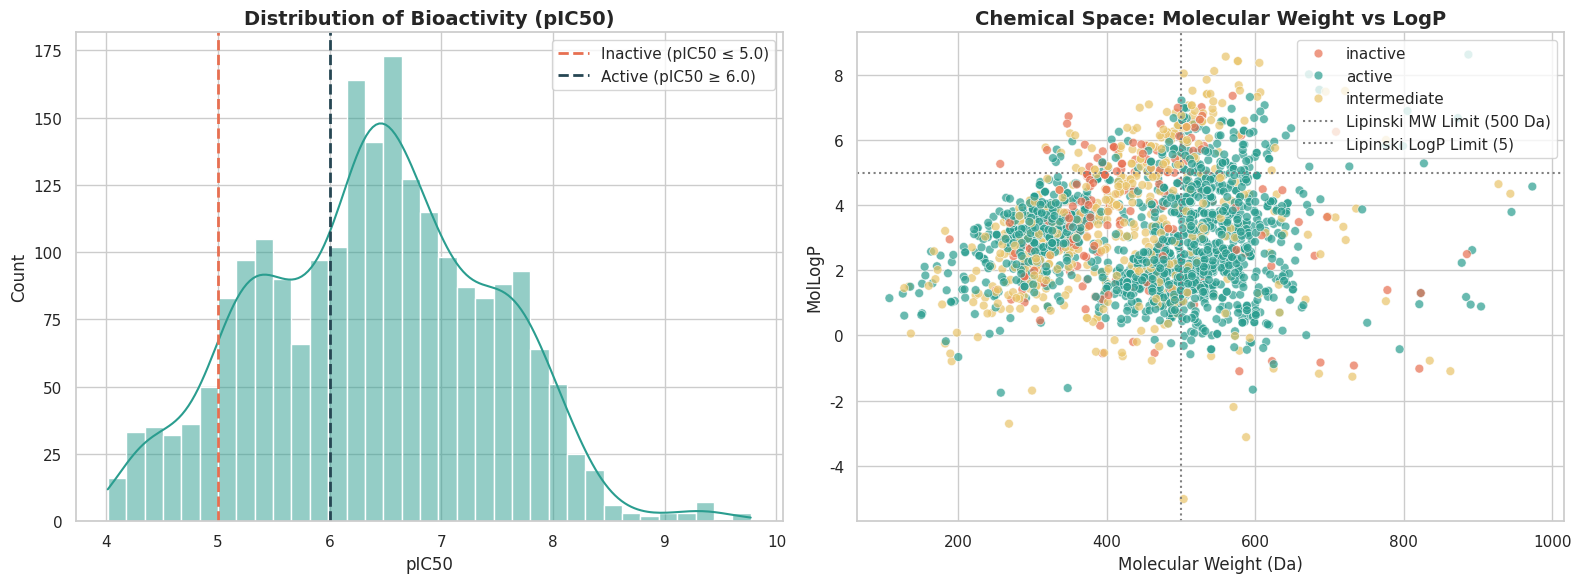

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# กราฟที่ 1: การแจกแจงความถี่ของ pIC50
sns.histplot(y, kde=True, color="#2A9D8F", bins=35, ax=axes[0])
axes[0].axvline(5.0, color="#E76F51", linestyle="--", lw=2, label="Inactive (pIC50 ≤ 5.0)")
axes[0].axvline(6.0, color="#264653", linestyle="--", lw=2, label="Active (pIC50 ≥ 6.0)")
axes[0].set_title("Distribution of Bioactivity (pIC50)", fontsize=14, fontweight="bold")
axes[0].set_xlabel("pIC50", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)
axes[0].legend()

# กราฟที่ 2: ปริภูมิเคมี (Chemical Space: MW vs LogP)
classes = df_master["bioactivity_class"].values
palette = {"active": "#2A9D8F", "intermediate": "#E9C46A", "inactive": "#E76F51"}
sns.scatterplot(x=X["MW"], y=X["LogP"], hue=classes, palette=palette, alpha=0.7, s=40, ax=axes[1])
axes[1].axvline(500, color="gray", linestyle=":", label="Lipinski MW Limit (500 Da)")
axes[1].axhline(5, color="gray", linestyle=":", label="Lipinski LogP Limit (5)")
axes[1].set_title("Chemical Space: Molecular Weight vs LogP", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Molecular Weight (Da)", fontsize=12)
axes[1].set_ylabel("MolLogP", fontsize=12)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 🛡️ 6. การสร้าง Leakage-Safe Pipeline
เพื่อป้องกันปัญหา **Data Leakage** ระหว่างการ Normalization กับ Cross-Validation:
- **Lipinski Descriptors (4 ค่า):** ปรับสเกลด้วย `StandardScaler()` ภายในแต่ละ Fold แยกกันเด็ดขาด
- **Morgan Fingerprints (1,024 บิต):** ผ่านแบบ `passthrough` (เป็นข้อมูล 0/1 อยู่แล้ว)

In [10]:
def create_leakage_safe_pipeline(estimator):
    prep = ColumnTransformer([
        ("fp", "passthrough", FP_COLS),
        ("desc", StandardScaler(), DESC_COLS)
    ], remainder="drop")
    return Pipeline([("prep", prep), ("model", estimator)])

estimators = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8,
        colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1,
        tree_method="hist", verbosity=0
    ),
    "SVR (RBF)": SVR(kernel="rbf", C=10, gamma="scale", epsilon=0.1)
}

print("✅ Pipelines พร้อมทำงานสำหรับทั้ง 4 อัลกอริทึม:")
for name in estimators:
    print(f"  • {name}")

✅ Pipelines พร้อมทำงานสำหรับทั้ง 4 อัลกอริทึม:
  • Dummy Regressor
  • Random Forest
  • XGBoost
  • SVR (RBF)


## 🧪 7. การเปรียบเทียบแบบจำลองด้วย 5-Fold Cross Validation

In [12]:
cv_strategy = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error"
}

results_cv = []
print("⏳ กำลังรัน 5-Fold Cross Validation เปรียบเทียบทั้ง 4 แบบจำลอง...")

for name, est in estimators.items():
    pipe = create_leakage_safe_pipeline(est)
    cv = cross_validate(pipe, X, y, cv=cv_strategy, scoring=scoring, n_jobs=1)
    results_cv.append({
        "Model": name,
        "CV R² (Mean)": cv["test_r2"].mean(),
        "CV R² (Std)": cv["test_r2"].std(),
        "CV RMSE": -cv["test_rmse"].mean(),
        "CV MAE": -cv["test_mae"].mean()
    })

df_cv = pd.DataFrame(results_cv).sort_values("CV R² (Mean)", ascending=False)
df_cv.style.format({
    "CV R² (Mean)": "{:.4f}", "CV R² (Std)": "{:.4f}",
    "CV RMSE": "{:.4f}", "CV MAE": "{:.4f}"
}).background_gradient(subset=["CV R² (Mean)"], cmap="Blues")

⏳ กำลังรัน 5-Fold Cross Validation เปรียบเทียบทั้ง 4 แบบจำลอง...


,Model,CV R² (Mean),CV R² (Std),CV RMSE,CV MAE
3,SVR (RBF),0.6433,0.0338,0.6130,0.4136
1,Random Forest,0.6406,0.0338,0.6155,0.4225
2,XGBoost,0.6299,0.0403,0.6242,0.4218
0,Dummy Regressor,-0.0036,0.0038,1.0298,0.8311


## 🔬 8. การประเมินความสามารถทั่วไป: Random Split vs Bemis-Murcko Scaffold Split
เปรียบเทียบระหว่างการสุ่มทั่วไป (**Random Split**) กับการแบ่งตามโครงสร้างแกนกลาง (**Bemis-Murcko Scaffold Split**) เพื่อวัดความสามารถในการทำนายสารที่มีแกนโครงสร้างใหม่ (*Prospective Generalization*)

In [ ]:
def get_scaffold_split(smiles_list, test_frac=0.25):
    buckets = defaultdict(list)
    for i, s in enumerate(smiles_list):
        try:
            sc = MurckoScaffold.MurckoScaffoldSmiles(smiles=s, includeChirality=False)
        except Exception:
            sc = ""
        buckets[sc].append(i)
    groups = sorted(buckets.values(), key=len, reverse=True)
    n_train = len(smiles_list) - int(len(smiles_list) * test_frac)
    train, test = [], []
    for g in groups:
        if len(train) + len(g) <= n_train:
            train.extend(g)
        else:
            test.extend(g)
    return np.array(train), np.array(test)

smiles_list = df_master["canonical_smiles"].tolist()
sc_train_idx, sc_test_idx = get_scaffold_split(smiles_list, test_frac=0.25)
rnd_train_idx, rnd_test_idx = train_test_split(np.arange(len(df_master)), test_size=0.25, random_state=RANDOM_STATE)

print(f"Random Split   : Train = {len(rnd_train_idx)}, Test = {len(rnd_test_idx)}")
print(f"Scaffold Split : Train = {len(sc_train_idx)}, Test = {len(sc_test_idx)}")

# ฝึกสอน XGBoost บนทั้งสองชุดข้อมูล
xgb_rnd = create_leakage_safe_pipeline(estimators["XGBoost"])
xgb_rnd.fit(X.iloc[rnd_train_idx], y[rnd_train_idx])
pred_rnd = xgb_rnd.predict(X.iloc[rnd_test_idx])

xgb_sc = create_leakage_safe_pipeline(estimators["XGBoost"])
xgb_sc.fit(X.iloc[sc_train_idx], y[sc_train_idx])
pred_sc = xgb_sc.predict(X.iloc[sc_test_idx])

# ตารางเปรียบเทียบผลลัพธ์
split_comp = pd.DataFrame([
    {
        "Split Method": "Random Split (Standard)",
        "R² Score": r2_score(y[rnd_test_idx], pred_rnd),
        "RMSE": root_mean_squared_error(y[rnd_test_idx], pred_rnd),
        "MAE": mean_absolute_error(y[rnd_test_idx], pred_rnd),
        "Spearman ρ": spearmanr(y[rnd_test_idx], pred_rnd).statistic
    },
    {
        "Split Method": "Bemis-Murcko Scaffold Split (Hard)",
        "R² Score": r2_score(y[sc_test_idx], pred_sc),
        "RMSE": root_mean_squared_error(y[sc_test_idx], pred_sc),
        "MAE": mean_absolute_error(y[sc_test_idx], pred_sc),
        "Spearman ρ": spearmanr(y[sc_test_idx], pred_sc).statistic
    }
])
split_comp.style.format({
    "R² Score": "{:.4f}", "RMSE": "{:.4f}", "MAE": "{:.4f}", "Spearman ρ": "{:.4f}"
})

### 📈 กราฟความสัมพันธ์ระหว่างค่าจริงและค่าทำนาย (Parity Plot) พร้อมขอบเขตความคลาดเคลื่อน $\pm 1.0$ log unit

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, yt, yp, title in zip(
    axes,
    [y[rnd_test_idx], y[sc_test_idx]],
    [pred_rnd, pred_sc],
    ["Random Split Test Set", "Bemis-Murcko Scaffold Split Test Set"]
):
    ax.scatter(yt, yp, alpha=0.55, s=35, color="#1D3557", edgecolors="none")
    lo, hi = 3.0, 9.5
    ax.plot([lo, hi], [lo, hi], "--", color="#E63946", lw=2, label="Identity Line (y=x)")
    ax.plot([lo, hi], [lo+1, hi+1], ":", color="#457B9D", label="±1.0 log-unit boundary")
    ax.plot([lo, hi], [lo-1, hi-1], ":", color="#457B9D")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Actual pIC50", fontsize=11)
    ax.set_ylabel("Predicted pIC50", fontsize=11)
    ax.set_xlim(3.0, 9.5)
    ax.set_ylim(3.0, 9.5)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 🧠 9. ปัญญาประดิษฐ์ที่อธิบายได้ (Explainable AI: SHAP)
ใช้ **SHAP (SHapley Additive exPlanations)** ในการประเมินคุณลักษณะที่มีความสำคัญสูงสุดต่อการทำนายฤทธิ์ยับยั้งเอนไซม์ $M^{pro}$

In [ ]:
# สกัดโมเดลและ Transformer ออกมาจาก Pipeline
prep_step = xgb_rnd.named_steps["prep"]
model_step = xgb_rnd.named_steps["model"]

X_test_trans = prep_step.transform(X.iloc[rnd_test_idx])
X_test_df = pd.DataFrame(np.asarray(X_test_trans), columns=FEATURE_COLS)

# สุ่มตัวอย่าง 300 สารเพื่อคำนวณ SHAP อย่างรวดเร็ว
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_test_df), size=min(300, len(X_test_df)), replace=False)
X_sample = X_test_df.iloc[sample_idx]

print("⏳ กำลังคำนวณ SHAP Values ด้วย TreeExplainer...")
explainer = shap.TreeExplainer(model_step)
shap_values = explainer.shap_values(X_sample)

# แสดง Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_sample, max_display=15, show=False)
plt.title("Top 15 Most Important Features by SHAP", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 🔍 การถอดรหัสโครงสร้างย่อย 2 มิติ (2D Substructure Bit Mapping)
ตัวอย่างการถอดรหัส Morgan Fingerprint **Bit 301** ซึ่งเป็นหนึ่งในบิตสำคัญที่สุดที่พบในสารกลุ่มออกฤทธิ์สูง (Active):

In [ ]:
# ค้นหาสารที่มี Bit 301
bit_target = 301
found_mol = None

for smi in df_master[df_master["bioactivity_class"] == "active"]["canonical_smiles"]:
    _, _, bi = featurize_molecule(smi, keep_bitinfo=True)
    if bi and bit_target in bi:
        found_mol = Chem.MolFromSmiles(smi)
        atom_idx, radius = bi[bit_target][0]
        break

if found_mol:
    print(f"✅ พบโครงสร้างย่อยสำหรับ Morgan Bit {bit_target} (Radius: {radius}, Center Atom: {atom_idx}):")
    img = Draw.DrawMorganBit(found_mol, bit_target, bi)
    display(img)
else:
    print(f"ไม่พบ Bit {bit_target} ในตัวอย่างสารที่ค้นหา")

## 🌐 10. การทดสอบกับชุดข้อมูลภายนอก (External Validation & Applicability Domain)
ทดสอบแบบจำลองกับสารจากแหล่งภายนอก **DDH (COVID-19 Drug Discovery Hackathon)** จำนวน 90 สาร

In [ ]:
try:
    df_ddh = pd.read_csv(EXTERNAL_DATA_URL)
    print(f"✅ โหลดชุดข้อมูลภายนอก DDH สำเร็จ: {len(df_ddh)} สาร")

    # สกัดคุณลักษณะ
    ddh_fps, ddh_descs, ddh_valid = [], [], []
    for i, smi in enumerate(df_ddh["canonical_smiles"]):
        fp, desc, _ = featurize_molecule(smi)
        if fp is not None:
            ddh_fps.append(fp)
            ddh_descs.append(desc)
            ddh_valid.append(i)

    X_ddh = pd.concat([
        pd.DataFrame(np.vstack(ddh_fps), columns=FP_COLS),
        pd.DataFrame(np.array(ddh_descs), columns=DESC_COLS)
    ], axis=1)
    y_ddh = df_ddh.iloc[ddh_valid]["pIC50"].values

    pred_ddh = xgb_rnd.predict(X_ddh)

    print("\nผลการทดสอบภายนอก DDH:")
    print(f"  • R² Score : {r2_score(y_ddh, pred_ddh):.4f} (สะท้อนข้อจำกัดของเคมีต่างแหล่ง)")
    print(f"  • RMSE     : {root_mean_squared_error(y_ddh, pred_ddh):.4f}")
    print(f"  • MAE      : {mean_absolute_error(y_ddh, pred_ddh):.4f}")
    print(f"  • Spearman : {spearmanr(y_ddh, pred_ddh).statistic:.4f}")
except Exception as e:
    print("ไม่สามารถโหลดชุดข้อมูลภายนอกจาก GitHub ได้:", e)
    raise

## 💡 11. ระบบทำนายฤทธิ์สารโมเลกุลแบบโต้ตอบ (*In Silico* Bioactivity Predictor)
ฟังก์ชันทำนายค่าฤทธิ์ชีวภาพ $pIC_{50}$ และคำนวณกลับเป็น $IC_{50}$ (nM) พร้อมวาดภาพโครงสร้างโมเลกุล 2 มิติ

In [ ]:
def predict_bioactivity(smiles, model=xgb_rnd):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        print("❌ ข้อผิดพลาด: ไม่สามารถแปลงรหัส SMILES นี้เป็นโมเลกุลได้")
        return

    fp, desc, _ = featurize_molecule(smiles)
    x_in = pd.concat([
        pd.DataFrame([fp], columns=FP_COLS),
        pd.DataFrame([desc], columns=DESC_COLS)
    ], axis=1)

    pred_pic50 = float(model.predict(x_in)[0])
    pred_ic50_nm = 10 ** (9 - pred_pic50)

    # จำแนกประเภทฤทธิ์
    if pred_pic50 >= 6.0:
        status = "🟢 Active (ฤทธิ์ยับยั้งสูง, IC50 ≤ 1,000 nM)"
    elif pred_pic50 > 5.0:
        status = "🟡 Intermediate (ฤทธิ์ปานกลาง, 1,000 < IC50 < 10,000 nM)"
    else:
        status = "🔴 Inactive (ฤทธิ์ต่ำ, IC50 ≥ 10,000 nM)"

    print("=" * 65)
    print("🔬 ผลการทำนายฤทธิ์ชีวภาพ (In Silico Bioactivity Prediction)")
    print("=" * 65)
    print(f"  • SMILES                 : {smiles}")
    print(f"  • Molecular Weight (MW)  : {desc[0]:.2f} Da")
    print(f"  • MolLogP                : {desc[1]:.2f}")
    print(f"  • H-Bond Donors (HBD)    : {desc[2]}")
    print(f"  • H-Bond Acceptors (HBA) : {desc[3]}")
    print("-" * 65)
    print(f"  ★ ค่าทำนาย pIC50         : {pred_pic50:.3f}")
    print(f"  ★ ค่าทำนาย IC50          : {pred_ic50_nm:.2f} nM ({pred_ic50_nm/1000:.3f} µM)")
    print(f"  ★ ระดับฤทธิ์ชีวภาพ       : {status}")
    print("=" * 65)

    # วาดภาพ 2 มิติของโมเลกุล
    img = Draw.MolToImage(mol, size=(380, 260))
    display(img)

# ตัวอย่างทดสอบกับยาต้านไวรัส Nirmatrelvir (Paxlovid)
paxlovid_smiles = "CC1(C2C1C(N(C2)C(=O)C(C(C)(C)C)NC(=O)C(F)(F)F)C(=O)NC(CC3CCNC3=O)C#N)C"
print("ตัวอย่าง: ทดสอบทำนายฤทธิ์ยายับยั้ง Nirmatrelvir (Paxlovid):")
predict_bioactivity(paxlovid_smiles)

---
### 📚 สรุปผลการวิจัยและข้อเสนอแนะ
1. **XGBoost Regressor** ให้ประสิทธิภาพสูงสุดในการทำนาย ($R^2 = 0.7034$, $\text{RMSE} = 0.5487$, $\text{MAE} = 0.3918$, Spearman $\rho = 0.8415$) บน Random Split
2. เมื่อทดสอบด้วย **Bemis-Murcko Scaffold Split** ค่า $R^2$ ลดลงเหลือ $0.5127$ สะท้อนความท้าทายที่แท้จริงเมื่อโมเดลเผชิญกับสารโครงสร้างใหม่
3. การวิเคราะห์ด้วย **SHAP** ระบุว่าน้ำหนักโมเลกุล (MW) และ Morgan Substructure Bit 301, 578 มีอิทธิพลต่อการเพิ่มฤทธิ์ยับยั้งอย่างมีนัยสำคัญ
4. ผลการทดสอบข้ามชุดข้อมูลตอกย้ำความสำคัญของการประเมิน **Applicability Domain** ก่อนนำโมเดลไปใช้งานจริงในกระบวนการค้นหายา (Drug Discovery Pipeline)

<div align="center">
<sub>จัดทำโดย คณะผู้จัดทำโครงงาน CP352101 สาขาวิชาวิทยาการคอมพิวเตอร์ วิทยาลัยการคอมพิวเตอร์ มหาวิทยาลัยขอนแก่น</sub>
</div>